# 05 Hybrid kinetic-ML models

ML predicts each jar's San parameters from dose and raw-water T0; the San equation then gives the full curve. Same leave-one-day-out folds and scoring as notebook 03. Tuning (inner GroupKFold on training days) scores the reconstructed curves. Predictions are cached in `results/predictions/05/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import time
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.exceptions import ConvergenceWarning

from src.config import DATA_PROC, RESULTS, SED_TIMES
from src.features import make_table
from src.metrics import summarise, non_monotone_share
from src import hybrid as H
from src import kinetics as kin
from src import style

style.apply()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

N_TRIALS = 15
SUBSET_DAYS = None
FEATURE_SETS = {"core": ["dose", "log_t0_raw"], "full": ["dose", "log_t0_raw", "speed", "mtime"]}
TIMES = SED_TIMES[1:]

PRED_DIR = RESULTS / "predictions" / "05"
MET_DIR = RESULTS / "metrics"
for p in (PRED_DIR, MET_DIR):
    p.mkdir(parents=True, exist_ok=True)

## 1. Jar table

In [2]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
if SUBSET_DAYS:
    long = long[long["day"].isin(sorted(long["day"].unique())[:SUBSET_DAYS])]
tab = make_table(long, level="cell")
fits = pd.read_csv(DATA_PROC / "kinetic_fits.csv")

jars = tab.drop_duplicates("run").set_index("run")[["day", "dose", "log_t0_raw", "t0_raw", "speed", "mtime"]].sort_index()
Y = tab.pivot(index="run", columns="sed", values="log_ratio").loc[jars.index, TIMES].to_numpy()
groups = jars["day"].to_numpy()

P_fit = {}
for form in H.FORMS:
    f = fits[fits["model"] == form].set_index("run").loc[jars.index, H.params_of(form)]
    P_fit[form] = f.to_numpy()
print(len(jars), "jars,", jars["day"].nunique(), "days | forms:", H.FORMS)

168 jars, 22 days | forms: ['san', 'san_floor']


Oracle: each jar's own fitted parameters with T0 = T0,raw. Uses test-day data, so it is a reference for the kinetic-form error, not a model.

In [3]:
oracle = {form: H.log_shape(form, P_fit[form], TIMES) for form in H.FORMS}
for form, o in oracle.items():
    print(f"{form:10s} oracle RMSE (log10): {np.sqrt(np.mean((o - Y) ** 2)):.4f}")

san        oracle RMSE (log10): 0.0245
san_floor  oracle RMSE (log10): 0.0202


## 2. Run

In [4]:
def to_long(log_ratio, name, fs, P=None, form=None):
    out = pd.DataFrame(log_ratio, index=jars.index, columns=TIMES).stack().rename("pred_ratio").reset_index()
    out.columns = ["run", "sed", "pred_ratio"]
    out = out.merge(tab[["run", "sed", "day", "t0_raw", "log_turb", "log_t0_raw"]], on=["run", "sed"])
    out["pred"] = out["pred_ratio"] + out["log_t0_raw"]
    out = out.assign(model=name, fset=fs, split="lodo", std=np.nan)
    if P is not None:
        for j, prm in enumerate(H.params_of(form)):
            out[f"p_{prm}"] = out["run"].map(dict(zip(jars.index, P[:, j])))
    return out.drop(columns=["pred_ratio", "log_t0_raw"])


for form in H.FORMS:
    path = PRED_DIR / f"oracle_{form}__core__lodo.csv"
    if not path.exists():
        to_long(oracle[form], f"oracle_{form}", "core", P_fit[form], form).to_csv(path, index=False)

for fs, feats in FEATURE_SETS.items():
    X = jars[feats].to_numpy(float)
    for form in H.FORMS:
        Z = H.to_targets(P_fit[form], form)
        for name in H.REGRESSORS:
            label = f"hyb_{form}_{name}"
            path = PRED_DIR / f"{label}__{fs}__lodo.csv"
            if path.exists():
                continue
            t = time.time()
            P_hat, params = H.run_lodo(name, form, X, Z, Y, groups, TIMES, feats, N_TRIALS)
            to_long(H.log_shape(form, P_hat, TIMES), label, fs, P_hat, form).to_csv(path, index=False)
            pd.DataFrame(params).assign(model=label, fset=fs).to_csv(PRED_DIR / f"params__{label}__{fs}.csv", index=False)
            print(f"{label:24s} {fs:5s} {time.time() - t:7.1f} s")

preds = pd.concat([pd.read_csv(p) for p in sorted(PRED_DIR.glob("*__*__lodo.csv"))], ignore_index=True)
print(preds.shape)

(22176, 13)


## 3. Scores and comparison with direct models

In [5]:
rows, by_day = [], []
for (m, fs), g in preds.groupby(["model", "fset"]):
    s, day_rmse = summarise(g)
    s.update({"model": m, "fset": fs, "split": "lodo", "non_monotone": non_monotone_share(g)})
    rows.append(s)
    by_day.append(day_rmse.rename("rmse").reset_index().assign(model=m, fset=fs, split="lodo"))
hyb = pd.DataFrame(rows).set_index(["fset", "split", "model"]).sort_index()
hyb.round(4).to_csv(MET_DIR / "05_scores.csv")
pd.concat(by_day, ignore_index=True).to_csv(MET_DIR / "05_scores_by_day.csv", index=False)

direct = []
for d in ["03", "04"]:
    for p in sorted((RESULTS / "predictions" / d).glob("*__lodo.csv")):
        if p.name.startswith("params"):
            continue
        g = pd.read_csv(p)
        if SUBSET_DAYS:
            g = g[g["day"].isin(jars["day"].unique())]
        s, _ = summarise(g)
        s.update({"model": g["model"].iloc[0], "fset": g["fset"].iloc[0], "split": "lodo",
                  "non_monotone": non_monotone_share(g)})
        direct.append(s)
direct = pd.DataFrame(direct).set_index(["fset", "split", "model"]) if direct else pd.DataFrame()

cols = ["day_rmse_mean", "day_rmse_sd", "r2_log", "rmse_log_60", "mae_removal60_pp", "non_monotone"]
comp = pd.concat([hyb.assign(kind="hybrid"), direct.assign(kind="direct")])
comp = comp.loc[comp.index.get_level_values("model") != "sed_mean"].sort_index()
comp.round(4).to_csv(MET_DIR / "05_comparison.csv")
comp.xs("core", level="fset")[cols + ["kind"]].sort_values("day_rmse_mean").round(4)

day_rmse_mean  day_rmse_sd  r2_log  rmse_log_60  mae_removal60_pp  non_monotone    kind
split model                                                                                                            
lodo  oracle_san_floor                 0.0190       0.0068  0.9948       0.0167            0.7190        0.0000  hybrid
      oracle_san                       0.0236       0.0065  0.9923       0.0216            1.0063        0.0000  hybrid
      hyb_san_svr                      0.1376       0.0764  0.6838       0.1884            8.0858        0.0000  hybrid
      hyb_san_floor_linear             0.1392       0.0818  0.6856       0.1855            7.8755        0.0000  hybrid
      mlp                              0.1396       0.0825  0.6762       0.1928            8.0525        0.0238  direct
      hyb_san_ridge_poly               0.1412       0.0794  0.6703       0.1925            8.6627        0.0000  hybrid
      ridge_poly                       0.1417       0.0838  0.6718       0.1886            8.0052        0.0060  direct
      svr                              0.1418       0.0805  0.6781       0.1898            8.0050        0.0000  direct
      hyb_san_floor_ridge_poly         0.1442       0.0854  0.6642       0.1890            8.4009        0.0000  hybrid
      hyb_san_floor_svr                0.1478       0.0827  0.6478       0.1949            8.2655        0.0000  hybrid
      hyb_san_mlp                      0.1478       0.0807  0.6570       0.1943            8.6197        0.0000  hybrid
      hyb_san_floor_et                 0.1505       0.0771  0.6530       0.1999            9.0845        0.0000  hybrid
      hyb_san_linear                   0.1509       0.0817  0.6556       0.1974            9.0028        0.0000  hybrid
      linear                           0.1509       0.0796  0.6526       0.1910            8.2586        0.0000  direct
      hyb_san_et                       0.1511       0.0712  0.6518       0.2007            9.2085        0.0000  hybrid
      hyb_san_floor_mlp                0.1542       0.0922  0.6128       0.2016            8.8585        0.0000  hybrid
      hgb                              0.1555       0.0723  0.6110       0.1986            9.0616        0.0000  direct
      rf                               0.1570       0.0749  0.6259       0.2016            8.7535        0.0000  direct
      et                               0.1574       0.0754  0.6199       0.2042            8.7471        0.0000  direct
      tabpfn                           0.1592       0.0808  0.6055       0.2099            8.7637        0.0000  direct
      gp                               0.2811       0.0845 -0.0026       0.2910           13.3229        0.1369  direct

In [6]:
comp.xs("full", level="fset")[cols + ["kind"]].sort_values("day_rmse_mean").round(4)

day_rmse_mean  day_rmse_sd  r2_log  rmse_log_60  mae_removal60_pp  non_monotone    kind
split model                                                                                                            
lodo  hyb_san_et                       0.1185       0.0646  0.7845       0.1599            7.4484        0.0000  hybrid
      et                               0.1193       0.0690  0.7744       0.1633            7.4896        0.0000  direct
      hyb_san_floor_et                 0.1212       0.0688  0.7678       0.1684            7.9073        0.0000  hybrid
      tabpfn                           0.1215       0.0691  0.7637       0.1693            7.6424        0.0000  direct
      svr                              0.1229       0.0584  0.7464       0.1653            8.2016        0.0000  direct
      hgb                              0.1281       0.0635  0.7247       0.1699            7.6154        0.0000  direct
      hyb_san_floor_linear             0.1286       0.0680  0.7034       0.1968            9.3257        0.0000  hybrid
      hyb_san_mlp                      0.1287       0.0619  0.7375       0.1810            9.5193        0.0000  hybrid
      hyb_san_svr                      0.1289       0.0646  0.7293       0.1802            9.4234        0.0000  hybrid
      hyb_san_floor_svr                0.1296       0.0650  0.7239       0.1873            9.7643        0.0000  hybrid
      linear                           0.1299       0.0579  0.7274       0.1694            8.3396        0.0000  direct
      hyb_san_linear                   0.1325       0.0682  0.6982       0.1999           10.4350        0.0000  hybrid
      hyb_san_floor_ridge_poly         0.1347       0.0677  0.6993       0.1949            9.4689        0.0000  hybrid
      rf                               0.1355       0.0755  0.7175       0.1747            7.6415        0.0000  direct
      ridge_poly                       0.1371       0.0582  0.7049       0.1742            8.3305        0.0000  direct
      hyb_san_floor_mlp                0.1403       0.0771  0.6926       0.1925           10.0141        0.0000  hybrid
      hyb_san_ridge_poly               0.1454       0.0677  0.6484       0.2024            9.7877        0.0000  hybrid
      mlp                              0.1598       0.1138  0.4282       0.2367           10.2765        0.0357  direct
      gp                               0.2299       0.0892  0.2822       0.2483           10.8477        0.1488  direct

figures/hybrid/fig01_hybrid_vs_direct.png


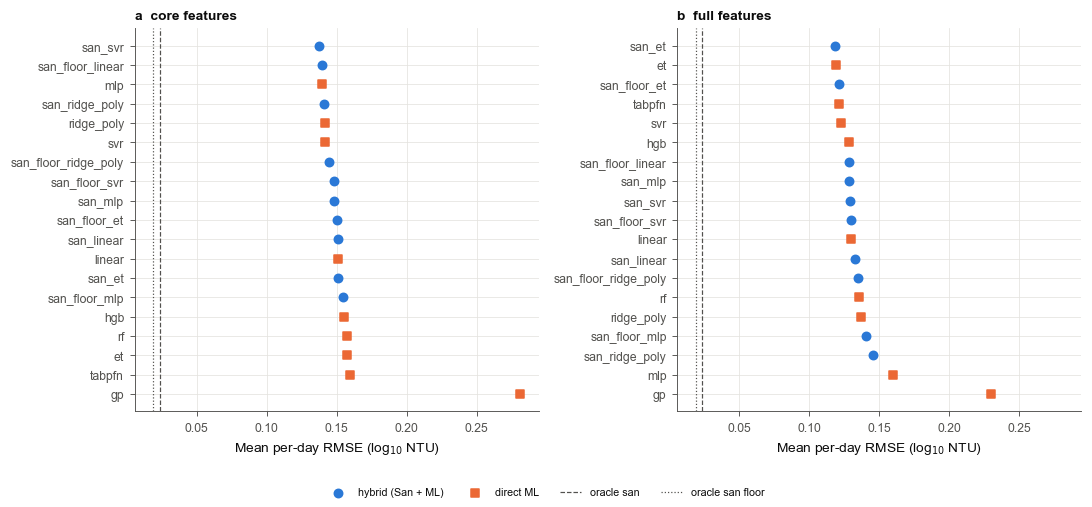

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True)
for ax, fs in zip(axes, ["core", "full"]):
    c = comp.xs(fs, level="fset").droplevel("split")
    c = c[~c.index.str.startswith("oracle")].sort_values("day_rmse_mean")
    ypos = np.arange(len(c))
    hybm = c["kind"] == "hybrid"
    ax.scatter(c.loc[hybm, "day_rmse_mean"], ypos[hybm.values], color=style.COLORS[0], marker=style.MARKERS[0],
               s=30, label="hybrid (San + ML)", zorder=3)
    ax.scatter(c.loc[~hybm, "day_rmse_mean"], ypos[~hybm.values], color=style.COLORS[1], marker=style.MARKERS[1],
               s=30, label="direct ML", zorder=3)
    for i, form in enumerate(H.FORMS):
        o = comp.loc[("core", "lodo", f"oracle_{form}"), "day_rmse_mean"]
        ax.axvline(o, color=style.INK2, lw=0.8, ls=["--", ":"][i], label=f"oracle {form.replace('_', ' ')}")
    ax.set_yticks(ypos, c.index.str.replace("hyb_", ""))
    ax.invert_yaxis()
    ax.set_xlabel("Mean per-day RMSE (log$_{10}$ NTU)")
    style.panel_label(ax, f"{'ab'[fs == 'full']}  {fs} features")
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=7)
print(style.save(fig, "fig01_hybrid_vs_direct", "hybrid"))
plt.show()

## 4. Parameter predictability (best hybrid, core features)

figures/hybrid/fig02_parameter_predictability.png


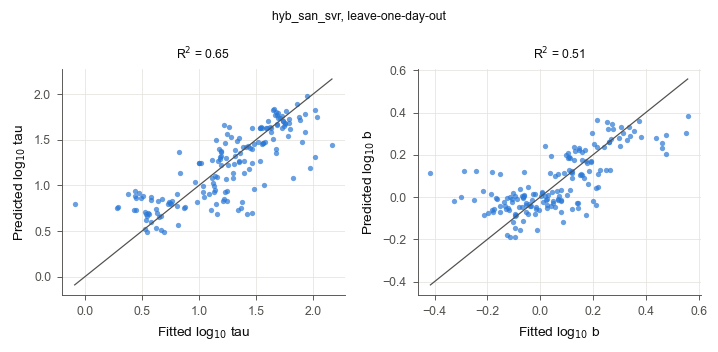

{'tau': 0.646, 'b': 0.513}


In [8]:
best = hyb.xs(("core", "lodo"))
best = best[~best.index.str.startswith("oracle")]["day_rmse_mean"].idxmin()
form = "san_floor" if best.startswith("hyb_san_floor") else "san"
g = preds[(preds["model"] == best) & (preds["fset"] == "core")].drop_duplicates("run").set_index("run").loc[jars.index]
names = H.params_of(form)

fig, axes = plt.subplots(1, len(names), figsize=(3.3 * len(names), 3.2))
r2 = {}
for ax, (j, prm) in zip(np.atleast_1d(axes), enumerate(names)):
    obs, pr = P_fit[form][:, j], g[f"p_{prm}"].to_numpy()
    if prm in H.LOG_PARAMS:
        obs, pr = np.log10(obs), np.log10(pr)
    r2[prm] = 1 - np.sum((obs - pr) ** 2) / np.sum((obs - obs.mean()) ** 2)
    ax.scatter(obs, pr, s=12, color=style.COLORS[0], alpha=0.7, lw=0)
    lim = [min(obs.min(), pr.min()), max(obs.max(), pr.max())]
    ax.plot(lim, lim, color=style.INK2, lw=0.8)
    lab = f"log$_{{10}}$ {prm}" if prm in H.LOG_PARAMS else prm
    ax.set_xlabel(f"Fitted {lab}")
    ax.set_ylabel(f"Predicted {lab}")
    ax.set_title(f"R$^2$ = {r2[prm]:.2f}", fontsize=8)
fig.suptitle(f"{best}, leave-one-day-out", fontsize=8)
fig.tight_layout()
print(style.save(fig, "fig02_parameter_predictability", "hybrid"))
plt.show()
print({k: round(float(v), 3) for k, v in r2.items()})

## 5. Example held-out curves

figures/hybrid/fig03_example_curves.png


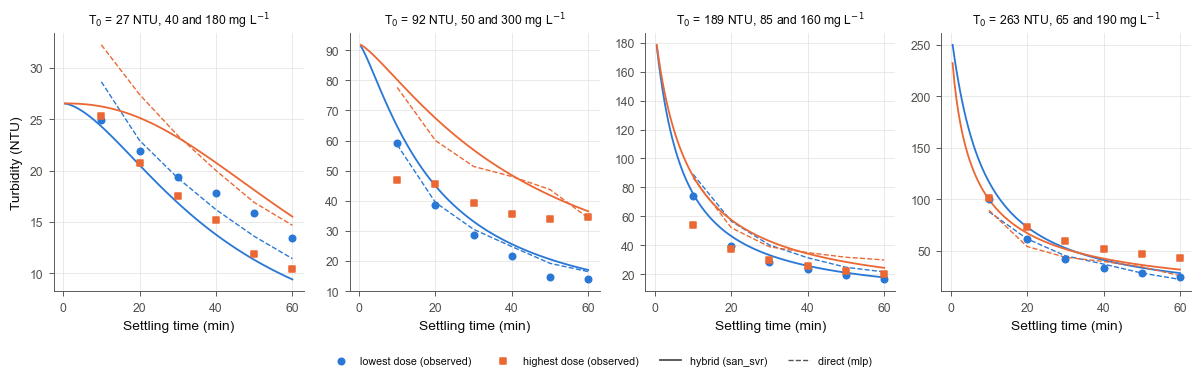

In [9]:
dir_best = None
if len(direct):
    d = direct.sort_index().xs(("core", "lodo"))
    dir_best = d[d.index != "sed_mean"]["day_rmse_mean"].idxmin()
    dpred = pd.concat([pd.read_csv(p) for d_ in ["03", "04"]
                       for p in (RESULTS / "predictions" / d_).glob(f"{dir_best}__core__lodo.csv")])

day_t0 = jars.groupby("day")["t0_raw"].median().sort_values()
show = day_t0.index[np.linspace(0, len(day_t0) - 1, 4).round().astype(int)]
tt = np.linspace(0.5, 60, 120)
obs_cells = long[long["sed"] > 0].groupby(["run", "sed"])["turb"].mean()

fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, day in zip(axes, show):
    js = jars[jars["day"] == day]
    pick = [js["dose"].idxmin(), js["dose"].idxmax()]
    for i, run in enumerate(pick):
        t0 = jars.loc[run, "t0_raw"]
        o = obs_cells.loc[run]
        ax.scatter(o.index, o.values, color=style.COLORS[i], marker=style.MARKERS[i], s=18, zorder=3,
                   label=["lowest dose", "highest dose"][i] + " (observed)")
        p = g.loc[run, [f"p_{n}" for n in names]].to_numpy(float)[None, :]
        ax.plot(tt, t0 * 10 ** H.log_shape(form, p, tt)[0], color=style.COLORS[i], lw=1.2)
        if dir_best:
            h = dpred[dpred["run"] == run].sort_values("sed")
            ax.plot(h["sed"], 10 ** h["pred"], color=style.COLORS[i], lw=0.9, ls="--")
    ax.set_title(f"T$_0$ = {day_t0[day]:.0f} NTU, {js['dose'].min():.0f} and {js['dose'].max():.0f} mg L$^{{-1}}$", fontsize=8)
    ax.set_xlabel("Settling time (min)")
axes[0].set_ylabel("Turbidity (NTU)")
axes[0].plot([], [], color=style.INK2, lw=1.2, label=f"hybrid ({best.replace('hyb_', '')})")
if dir_best:
    axes[0].plot([], [], color=style.INK2, lw=0.9, ls="--", label=f"direct ({dir_best})")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
print(style.save(fig, "fig03_example_curves", "hybrid"))
plt.show()

## 6. Key numbers

In [10]:
c = comp.xs(("core", "lodo"))
c = c[~c.index.str.startswith("oracle")]
key = {
    "best_hybrid_core": best,
    "best_hybrid_core_day_rmse": round(float(hyb.loc[("core", "lodo", best), "day_rmse_mean"]), 4),
    "best_direct_core": dir_best,
    "best_direct_core_day_rmse": round(float(c.loc[dir_best, "day_rmse_mean"]), 4) if dir_best else None,
    "oracle_san_day_rmse": round(float(hyb.loc[("core", "lodo", "oracle_san"), "day_rmse_mean"]), 4),
    "oracle_san_floor_day_rmse": round(float(hyb.loc[("core", "lodo", "oracle_san_floor"), "day_rmse_mean"]), 4),
    "param_r2_best": {k: round(float(v), 3) for k, v in r2.items()},
    "n_trials": N_TRIALS,
}
(MET_DIR / "05_key_numbers.json").write_text(json.dumps(key, indent=2))
pd.Series(key)

best_hybrid_core                            hyb_san_svr
best_hybrid_core_day_rmse                        0.1376
best_direct_core                                    mlp
best_direct_core_day_rmse                        0.1396
oracle_san_day_rmse                              0.0236
oracle_san_floor_day_rmse                         0.019
param_r2_best                {'tau': 0.646, 'b': 0.513}
n_trials                                             15
dtype: object